# Quant Assessment 2 — Adaptive Market Making and Relative Value

This is a fresh, unsolved local mock assessment. It uses the same synthetic simulator API as the first assessment but contains different tasks, decision rules, and risk-management objectives. It is not proprietary or evidence of a current employer assessment.

## Instructions

- Suggested timebox: **150 minutes**, followed by a review pass.
- Work from top to bottom and preserve requested names.
- Use only information available at or before the current date.
- Client actions are from the client's perspective; completed-trade actions are from the market maker's perspective.
- Restart the kernel before your final run.
- This notebook intentionally contains no solutions.

In [1]:
from pathlib import Path
import sys

_candidates = []
for _base in (Path.cwd(), *Path.cwd().parents):
    _candidates.extend((_base, _base / 'millennium-market-making-prep'))
PROJECT_ROOT = next((path for path in _candidates
                     if (path / 'AmplifyQuantTrading').is_dir()), None)
if PROJECT_ROOT is None:
    raise ModuleNotFoundError('Start Jupyter from the Python workspace')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from AmplifyQuantTrading import Data, Exchange, MarketMaker, HedgeFund as hf
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

hf.reset(seed=3030)
print('Assessment 2 environment ready')

Assessment 2 environment ready


In [2]:
STOCKS = ['AAPL', 'FB', 'AMZN', 'NFLX', 'GOOGL']
ETF = 'FAANG'
RANDOM_SEED = 3030
hf.reset(seed=RANDOM_SEED)

## Assessment map

1. Build validated market-data and quote objects.
2. Run an adaptive market maker with inventory limits.
3. Estimate rolling risk and rebalance ETF hedges only when necessary.
4. Trade a z-score-based real-versus-synthetic ETF strategy after costs.

# Challenge 1 — Reliable quote construction

Build a quote workflow that validates data instead of assuming every input is clean.

In [3]:
prices = Data.get_price_series('PricestoFeedserver')
price_requests = Data.get_price_requests('PriceRequeststoFeedserver')
print('price rows:', len(prices), 'request rows:', len(price_requests))
print('sample:', prices[:2], price_requests[:2])

price rows: 6846 request rows: 100
sample: [['AAPL', 0, 74.7], ['AMZN', 0, 1953.0]] [['FB', 0, 3010], ['AAPL', 10000, 6929]]


## Task 1A — Validate row shapes

Write `validate_rows(prices, requests)`. Every price row must contain ticker, date, positive finite price. Every request must contain ticker, date, and positive integer volume. Return `True`; raise `ValueError` with a useful message for invalid input.

In [4]:
from numbers import Integral, Real
import math

def validate_rows(prices, requests):
    stocks = STOCKS.copy()
    stocks.append(ETF)
    for ticker, date, price in prices:
        if ticker not in stocks:
            raise ValueError(f"Unknown ticker: {ticker}")
        if not isinstance(date, int):
            raise ValueError(f"Invalid date: {date}")
        if not isinstance(price, float) or not math.isfinite(price) or price <= 0:
            raise ValueError(f"Invalid price: {price}")

    for ticker, date, volume in requests:
        if ticker not in stocks:
            raise ValueError(f"Unknown ticker: {ticker}")
        if not isinstance(date, int):
            raise ValueError(f"Invalid date: {date}")
        if not isinstance(volume, int) or volume <= 0:
            raise ValueError(f"Invalid volume: {volume}")

    return True


### Public check

The check reports only whether the supplied synthetic feeds pass your validator.

In [5]:
try:
    valid = validate_rows(prices, price_requests)
    print('Task 1A:', 'OK' if valid is True else 'return True when valid')
except Exception as exc:
    print('Task 1A needs work:', type(exc).__name__, exc)

Task 1A: OK


## Task 1B — Construct a unique price lookup

Build `price_lookup` keyed by `(ticker, date)`. Reject duplicate keys rather than silently overwriting them.

In [6]:
price_lookup = {}

for ticker, date, price in prices:
    if (ticker, date) in price_lookup:
        raise ValueError(f"same ticker and date multiple times")
    price_lookup[(ticker, date)] = price

list(price_lookup.items())[:5]

[(('AAPL', 0), 74.7),
 (('AMZN', 0), 1953.0),
 (('FAANG', 0), 100.0),
 (('FB', 0), 194.44),
 (('GOOGL', 0), 1386.0)]

### Lookup check

The number of dictionary keys should equal the number of price rows.

In [7]:
print('lookup rows:', len(price_lookup), 'price rows:', len(prices))

lookup rows: 6846 price rows: 6846


## Task 1C — Create a dispersed request sample

Create `sample_requests` containing 12 requests spread across the first 48 request rows rather than simply taking the first 12. Preserve chronological order and do not mutate the feed.

In [8]:
sample_requests = []

permutation = np.random.permutation(48).tolist()
for index in permutation:
    sample_requests.append(price_requests[index])
sample_requests = sorted(sample_requests, key=lambda row: row[1])

### Sample check

Confirm the sample length, date order, and number of distinct tickers.

In [9]:
sample_dates = [row[1] for row in sample_requests]
print('rows:', len(sample_requests))
print('chronological:', sample_dates == sorted(sample_dates))
print('tickers:', sorted({row[0] for row in sample_requests}))

rows: 48
chronological: True
tickers: ['AAPL', 'AMZN', 'FB', 'GOOGL', 'NFLX']


## Task 1D — Enrich requests

Create `enriched_requests` as dictionaries with keys `ticker`, `date`, `volume`, and `ref_price`. Raise on a missing price.

In [10]:
enriched_requests = []

for ticker, date, volume in price_requests:
    key = (ticker, date)
    if key not in price_lookup:
        raise ValueError(f"no price for {ticker} on date {date}")
    ref_price = price_lookup[key]
    enriched_requests.append({'ticker': ticker, 'date': date, 'volume': volume, 'ref_price': ref_price})
    

### Enrichment check

Every sampled request should produce exactly one enriched record.

In [11]:
print('enriched rows:', len(enriched_requests))
print(enriched_requests[:2])

enriched rows: 100
[{'ticker': 'FB', 'date': 0, 'volume': 3010, 'ref_price': 194.44}, {'ticker': 'AAPL', 'date': 10000, 'volume': 6929, 'ref_price': 74.63}]


## Task 1E — Define `QuoteTicket`

Create a class with attributes `ticker`, `trade_volume`, `ref_price`, `bid_price`, `offer_price`, and `date`. Validate values inside `__init__`. Add readable `__str__` and constructor-like `__repr__` methods.

In [12]:
class QuoteTicket:
    def __init__(self, ticker, trade_volume, ref_price, bid_price, offer_price, date):
        self.ticker = ticker
        self.trade_volume = trade_volume
        self.ref_price = ref_price
        self.bid_price = bid_price
        self.offer_price = offer_price
        self.date = date
        self.__post_init__()

    def __post_init__(self):
        if not self.ticker or isinstance(self.trade_volume, bool) or not isinstance(self.trade_volume, int) or self.trade_volume <= 0:
            raise ValueError("need ticker and positive volume integer")
        if not all(math.isfinite(x) for x in (self.ref_price, self.bid_price, self.offer_price)):
            raise ValueError("prices must be finite")
        if self.ref_price <= 0 or self.bid_price <= 0 or self.bid_price > self.offer_price:
            raise ValueError("require 0 < bid <= offer and positive reference")

    def __str__(self):
        return (
            f"{self.ticker}: {self.trade_volume} shares, "
            f"bid {self.bid_price}, offer {self.offer_price}"
        )
    
    def __repr__(self):
        return (
            f"QuotedTrade(ticker={self.ticker!r}, "
            f"trade_volume={self.trade_volume!r}, "
            f"ref_price={self.ref_price!r}, "
            f"bid_price={self.bid_price!r}, "
            f"offer_price={self.offer_price!r}, "
            f"date={self.date!r})"
        )

## Task 1F — Size-sensitive quote width

Implement `size_adjusted_quote(ref_price, volume)`. Start 1% away on each side. Add another 0.25 percentage points on each side for volume above 3,000 and another 0.25 points above 6,000. Return `(bid, offer)` and validate inputs.

In [13]:
def size_adjusted_quote(ref_price, volume):
    if ref_price <= 0 or not isinstance(volume, int) or volume <=0:
        raise ValueError("wrong values for volume or price")
    if volume <= 3000:
        bid_price = ref_price * (1 - 0.01)
        offer_price = ref_price * (1 + 0.01)
    elif volume <= 6000:
        bid_price = ref_price * (1 - 0.0125)
        offer_price = ref_price * (1 + 0.0125)
    else:
        bid_price = ref_price * (1 - 0.015)
        offer_price = ref_price * (1 + 0.015)
    return bid_price, offer_price

### Quote examples

Print quotes for volumes 1,000, 4,000, and 7,000 at a reference price of 100. Width should increase monotonically.

In [14]:
for example_volume in (1000, 4000, 7000):
    try:
        print(example_volume, size_adjusted_quote(100.0, example_volume))
    except Exception as exc:
        print(type(exc).__name__, exc)

1000 (99.0, 101.0)
4000 (98.75, 101.25)
7000 (98.5, 101.49999999999999)


## Task 1G — Build sample quotes

Create one `QuoteTicket` per enriched request using your size-sensitive rule. Store them in `sample_quotes`.

In [15]:
sample_quotes = []

for request in enriched_requests:
    ticker, date, volume, price = request['ticker'], request['date'], request['volume'], request['ref_price']
    bid, offer = size_adjusted_quote(price, volume)
    sample_quotes.append(QuoteTicket(ticker, volume, price, bid, offer, date))

### Quote-log check

All quote fields should be present, and every bid should be below its offer.

In [16]:
quote_fields = ('ticker', 'trade_volume', 'ref_price', 'bid_price', 'offer_price', 'date')
quote_shape_ok = all(all(hasattr(q, field) for field in quote_fields) for q in sample_quotes)
quote_order_ok = all(q.bid_price < q.offer_price for q in sample_quotes)
print('shape:', quote_shape_ok, 'price order:', quote_order_ok)

shape: True price order: True


## Task 1H — Submit quotes and record responses

Reset the client to seed 3031, submit every sample quote once, and store results in `sample_responses`.

In [17]:
hf.reset(seed=3031)
sample_responses = []

for quote in sample_quotes:
    sample_responses.append(hf.show(quote))



### Response summary

Count buys, sells, and refusals without assuming that every action appears.

In [18]:
hf_responses = {'buy': 0, 'sell': 0, 'refuse': 0}
for answers in sample_responses:
    decision = answers.hf_action
    hf_responses[decision] += 1
hf_responses

{'buy': 56, 'sell': 38, 'refuse': 6}

## Task 1I — Define an execution record

Create `ExecutionRecord` with the eight fields expected by `MarketMaker.add_trade`: ticker, volume, execution price, maker action, reference, bid, offer, and date. Validate the maker action.

In [19]:
class ExecutionRecord:
    def __init__(self, ticker, trade_volume, trade_price, mm_action,
                 ref_price, bid_price, offer_price, date):
        self.ticker = ticker
        self.trade_volume = trade_volume
        self.trade_price = trade_price
        self.mm_action = mm_action
        self.ref_price = ref_price
        self.bid_price = bid_price
        self.offer_price = offer_price
        self.date = date
        self.__post_init__()

    def __post_init__(self):
        if self.mm_action not in {'buy', 'sell'}:
            raise ValueError("maker must buy or sell")

## Task 1J — Complete the sample workflow

Create a fresh `sample_mm`, log every quote, translate accepted client actions to opposite maker actions, and add completed executions. Refusals must not create executions.

In [20]:
sample_mm = MarketMaker.mm()

for quote in sample_quotes:
    sample_mm.add_quoted_trade(quote)

for response in sample_responses:
    if response.hf_action in {"buy", "sell"}:
        mm_action = "sell" if response.hf_action == "buy" else "buy"

        trade = ExecutionRecord(
            response.ticker,
            response.trade_volume,
            response.trade_price,
            mm_action,
            response.ref_price,
            response.bid_price,
            response.offer_price,
            response.date,
        )

        sample_mm.add_trade(trade)

### Challenge 1 summary

Report quote count, completed count, refusal count, and non-zero inventory.

In [21]:
quote_count = len(sample_mm.quoted_trades)
completed_count = len(sample_mm.completed_trades)
refusal_count = quote_count - completed_count

non_zero_inventory = {
    ticker: position.position_volume
    for ticker, position in sample_mm.current_positions.items()
    if position.position_volume != 0
}

print("Quote count:", quote_count)
print("Completed count:", completed_count)
print("Refusal count:", refusal_count)
print("Non-zero inventory:", non_zero_inventory)

Quote count: 100
Completed count: 94
Refusal count: 6
Non-zero inventory: {'FB': -20764, 'AAPL': -13420, 'AMZN': 1800, 'NFLX': 3324, 'GOOGL': -10444}


## Challenge 1 visualization

Plot reference, bid, and offer for the ticker with the most sample quotes. Use a title, labels, legend, and grid.

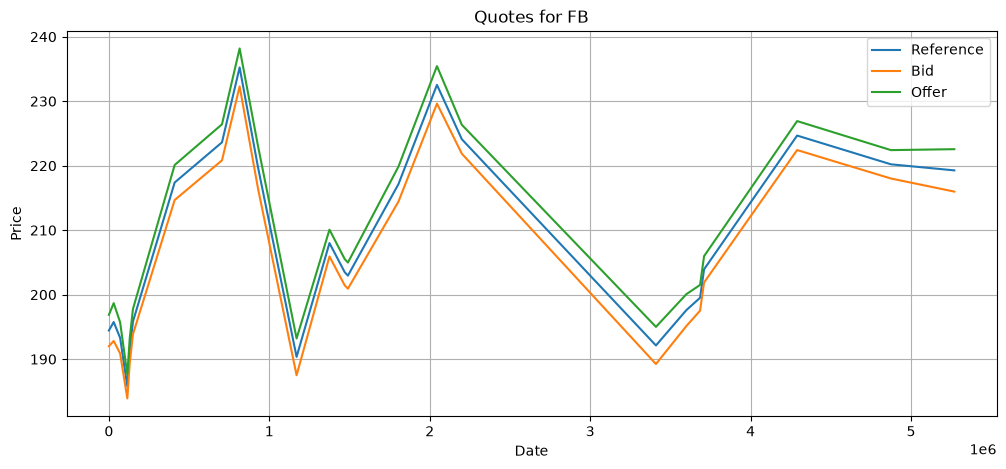

In [22]:
counts = {}

for quote in sample_quotes:
    ticker = quote.ticker
    counts[ticker] = counts.get(ticker, 0) + 1

most_quoted_ticker = max(counts, key=counts.get)

ticker_quotes = []

for quote in sample_quotes:
    if quote.ticker == most_quoted_ticker:
        ticker_quotes.append(quote)

ticker_quotes.sort(key=lambda quote: quote.date)

dates = [quote.date for quote in ticker_quotes]
ref = [quote.ref_price for quote in ticker_quotes]
bid = [quote.bid_price for quote in ticker_quotes]
offer = [quote.offer_price for quote in ticker_quotes]

plt.figure(figsize=(12, 5))
plt.plot(dates, ref, label="Reference")
plt.plot(dates, bid, label="Bid")
plt.plot(dates, offer, label="Offer")

plt.title(f"Quotes for {most_quoted_ticker}")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid()
plt.show()

### Challenge 1 reflection

In two or three sentences, explain why a larger client order should generally receive a wider quote and identify one disadvantage of widening too aggressively.

_Write your answer here before continuing._

A larger order can leave the market maker with substantial inventory that may be difficult or expensive to hedge, so the quote is widened to compensate for that additional risk. If the quote is widened too aggressively, clients may refuse it, reducing trading volume and potential spread profit.

# Challenge 2 — Adaptive market making with a hard risk limit

Run the extended request stream. Quote width depends on request size, quote center depends on inventory, and accepted trades that would breach a hard position limit must be rejected by your strategy.

In [23]:
mm = MarketMaker.mm()
prices = Data.get_price_series('PricestoFeedserverExtended')
price_requests = Data.get_price_requests('PriceRequeststoFeedserverExtended')
hf.reset(seed=3032)
POSITION_LIMIT = 30_000
print(len(prices), len(price_requests))

6846 520


In [24]:
prices[:2]

[['AAPL', 0, 74.7], ['AMZN', 0, 1953.0]]

## Task 2A — Adaptive quote helper

Implement `adaptive_quote(ref_price, volume, position, limit)`. Begin with the size-adjusted width from Challenge 1. Shift the quote center down when long and up when short, proportionally to `position / limit`. Cap the skew so prices remain sensible.

In [25]:
def adaptive_quote(ref_price, volume, position, limit):
    if limit <= 0:
        raise ValueError("Limit must be positive")

    if abs(position) > limit:
        position = limit if position > 0 else -limit
    if volume <= 3000:
        bid_price = ref_price * (1 - 0.01 - 0.01 * position / limit)
        offer_price = ref_price * (1 + 0.01 - 0.01 * position / limit)
    elif volume <= 6000:
        bid_price = ref_price * (1 - 0.0125 - 0.01 * position / limit)
        offer_price = ref_price * (1 + 0.0125 - 0.01 * position / limit)
    else:
        bid_price = ref_price * (1 - 0.015 - 0.01 * position / limit)
        offer_price = ref_price * (1 + 0.015 - 0.01 * position / limit)
    return bid_price, offer_price

In [26]:
for example_volume in (1000, 4000, 7000):
    try:
        print(example_volume, adaptive_quote(100.0, example_volume,10,100))
    except Exception as exc:
        print(type(exc).__name__, exc)

1000 (98.9, 100.9)
4000 (98.65, 101.15)
7000 (98.4, 101.4)


## Task 2B — Stateful request loop

For each request: find its price, inspect inventory, create and log a `QuoteTicket`, ask the client, translate accepted actions, and test the proposed new position against `POSITION_LIMIT`. Log only fills that remain within the limit. Track refusals, risk rejections, AAPL inventory, and quote width.

In [27]:
risk_rejections = 0
client_refusals = 0
aapl_dates = []
aapl_inventory = []
aapl_quote_width = []

prices_df = pd.DataFrame(prices, columns = ['ticker', 'date', 'price'])
price_requests_df = pd.DataFrame(price_requests, columns = ['ticker', 'date', 'volume'])

quotes_df = pd.merge(price_requests_df, prices_df, "left", ['ticker', 'date'], validate= 'many_to_one')
for row in quotes_df.itertuples(index=False):
    ticker, volume, price, date = row.ticker, row.volume, row.price, row.date
    position = mm.position(ticker)
    bid, offer = adaptive_quote(price, volume, position, POSITION_LIMIT)

    quote = QuoteTicket(ticker, volume, price, bid, offer, date)
    mm.add_quoted_trade(quote)

    hf_response = hf.show(quote)
    client_action = hf_response.hf_action
    if client_action not in {'buy', 'sell'}: 
        client_refusals += 1
    else:
        if client_action == 'buy':
            mm_action = 'sell'
            future_position = position - volume
        else:
            mm_action = 'buy'
            future_position = position + volume
        if np.abs(future_position) > POSITION_LIMIT:
            risk_rejections += 1
        else:
            trade = ExecutionRecord(hf_response.ticker, hf_response.trade_volume, hf_response.trade_price, mm_action, hf_response.ref_price, hf_response.bid_price, hf_response.offer_price, hf_response.date)
            mm.add_trade(trade)

    if ticker == "AAPL":
        aapl_dates.append(date)
        aapl_inventory.append(mm.position("AAPL"))
        aapl_quote_width.append(offer - bid)
    


### Loop summary

Print request, quote, completion, refusal, rejection, and maximum absolute inventory statistics.

In [28]:
request_count = len(price_requests)
quote_count = len(mm.quoted_trades)
completed_count = len(mm.completed_trades)

max_abs_ending_inventory = max(
    (abs(position.position_volume)
     for position in mm.current_positions.values()),
    default=0
)

print("Requests:", request_count)
print("Quotes:", quote_count)
print("Completed trades:", completed_count)
print("Client refusals:", client_refusals)
print("Risk rejections:", risk_rejections)
print("Maximum absolute ending inventory:", max_abs_ending_inventory)

print(
    "Counts reconcile:",
    quote_count == completed_count + client_refusals + risk_rejections
)

Requests: 520
Quotes: 520
Completed trades: 442
Client refusals: 63
Risk rejections: 15
Maximum absolute ending inventory: 13930
Counts reconcile: True


## Task 2C — Plot AAPL inventory

Plot inventory after each AAPL request. Add horizontal lines for zero and both position limits.

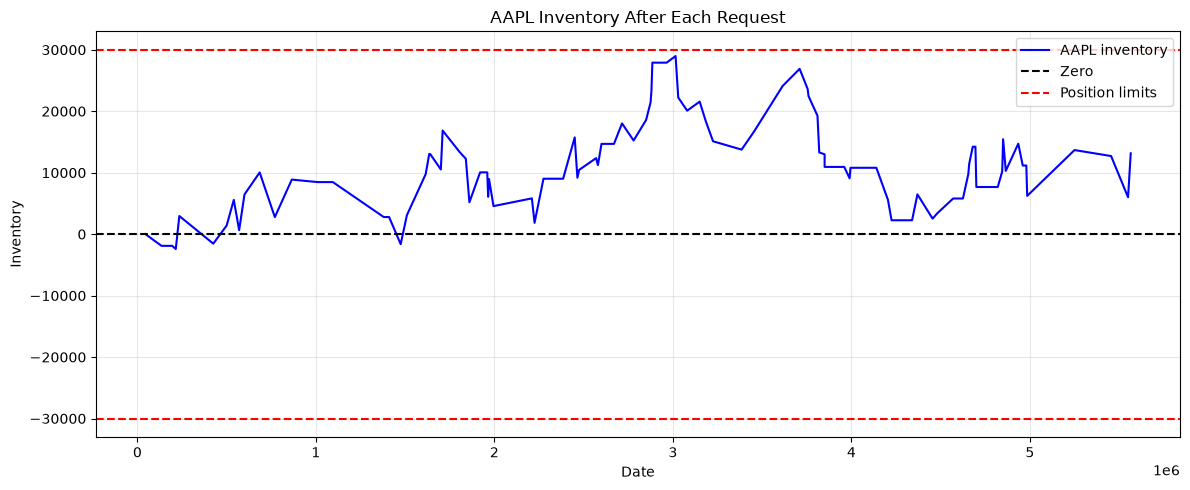

In [29]:
plt.figure(figsize=(12, 5))

plt.plot(
    aapl_dates,
    aapl_inventory,
    label="AAPL inventory",
    color="blue"
)

plt.axhline(0, color="black", linestyle="--", label="Zero")
plt.axhline(
    POSITION_LIMIT,
    color="red",
    linestyle="--",
    label="Position limits"
)
plt.axhline(
    -POSITION_LIMIT,
    color="red",
    linestyle="--"
)

plt.title("AAPL Inventory After Each Request")
plt.xlabel("Date")
plt.ylabel("Inventory")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Task 2D — Plot AAPL quote width

Plot `offer_price - bid_price` through time. Explain whether changes came from order size, inventory, or both.

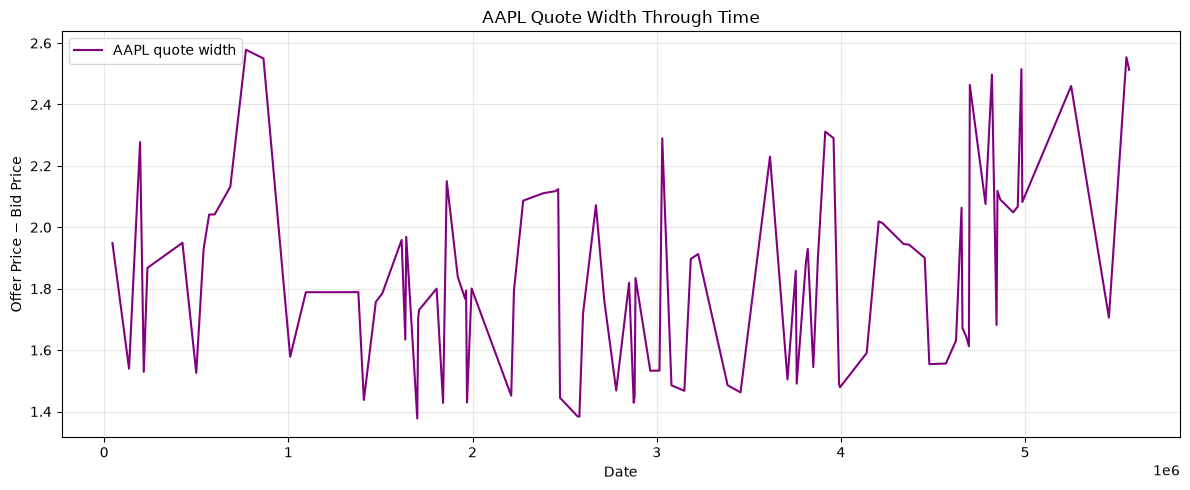

In [30]:
plt.figure(figsize=(12, 5))

plt.plot(
    aapl_dates,
    aapl_quote_width,
    color="purple",
    label="AAPL quote width"
)

plt.title("AAPL Quote Width Through Time")
plt.xlabel("Date")
plt.ylabel("Offer Price − Bid Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Task 2E — Risk-limit validation

Confirm that no final or historical recorded position exceeded the stated limit. Report the number and fraction of requests rejected by risk.

In [31]:
positions = {ticker: 0 for ticker in STOCKS}
absolute_inventory_history = []

for trade in mm.completed_trades:
    if trade.mm_action == "buy":
        positions[trade.ticker] += trade.trade_volume
    else:
        positions[trade.ticker] -= trade.trade_volume

    absolute_inventory_history.append(
        abs(positions[trade.ticker])
    )

limit_held = all(
    inventory <= POSITION_LIMIT
    for inventory in absolute_inventory_history
)

max_abs_inventory = max(
    absolute_inventory_history,
    default=0
)

print("Limit held throughout history:", limit_held)
print("Maximum absolute inventory:", max_abs_inventory)
print("Risk rejections:", risk_rejections)
print(f"Rejection rate: {risk_rejections / request_count:.2%}")

Limit held throughout history: True
Maximum absolute inventory: 29590
Risk rejections: 15
Rejection rate: 2.88%


### Challenge 2 reflection

Write three observations: whether the limit bound held, how inventory affected quote centers, and how rejected fills affect client service.

_Write your answer here before continuing._

1. The position limit held throughout the simulation because any fill that would have pushed inventory beyond ±30,000 was rejected.
2. Long inventory shifted the quote center downward to encourage clients to buy from the market maker, while short inventory shifted it upward to encourage clients to sell.
3. Risk rejections protected the market maker from excessive exposure, but they also meant that some client orders accepted at the quoted price were not completed, which could reduce client satisfaction and future order flow.

In [32]:
print('Challenge 2 complete when all preceding checks are meaningful.')

Challenge 2 complete when all preceding checks are meaningful.


# Research — Rolling volatility and rolling beta

Unlike a single full-sample beta, rolling estimates can reveal whether relationships change through time.

In [33]:
wide_prices = Data.get_price_series('PricestoFeedserverEtfUpdate', True)
print(wide_prices.head())

        AAPL     AMZN   FAANG      FB    GOOGL    NFLX
date                                                  
0      74.70  1953.00  100.00  196.44  1386.00  381.05
5000   74.04  1943.96   99.58  197.35  1376.61  381.11
10000  74.42  1935.27  100.06  197.76  1381.43  383.00
15000  75.27  1939.40  100.52  196.64  1400.90  382.86
20000  75.34  1971.73  100.90  198.90  1412.23  382.71


## Task 3A — Aligned returns

Create `returns` for all six assets using simple percentage returns. Do not forward-fill missing observations.

In [34]:
returns = wide_prices.pct_change().dropna()
print(returns.head())

           AAPL      AMZN     FAANG        FB     GOOGL      NFLX
date                                                             
5000  -0.008835 -0.004629 -0.004200  0.004632 -0.006775  0.000157
10000  0.005132 -0.004470  0.004820  0.002078  0.003501  0.004959
15000  0.011422  0.002134  0.004597 -0.005663  0.014094 -0.000366
20000  0.000930  0.016670  0.003780  0.011493  0.008088 -0.000392
25000  0.010220  0.007400  0.009514  0.014681  0.009623  0.022288


### Return check

Report shape, missing count, and first two rows.

In [35]:
print(returns.shape)
print(returns.isna().sum())
print(returns.head(2))

(1140, 6)
AAPL     0
AMZN     0
FAANG    0
FB       0
GOOGL    0
NFLX     0
dtype: int64
           AAPL      AMZN    FAANG        FB     GOOGL      NFLX
date                                                            
5000  -0.008835 -0.004629 -0.00420  0.004632 -0.006775  0.000157
10000  0.005132 -0.004470  0.00482  0.002078  0.003501  0.004959


## Task 3B — Rolling annualized volatility

Using a 60-observation window and 252-period annualization, create `rolling_volatility` for the five stocks. Preserve dates and leave early unavailable values as missing.

In [36]:
WINDOW = 60

rolling_volatility = returns[STOCKS].rolling(window=WINDOW).std() *np.sqrt(252)
print(rolling_volatility.dropna().head(5))

            AAPL        FB      AMZN      NFLX     GOOGL
date                                                    
300000  0.130844  0.168552  0.138140  0.157818  0.163027
305000  0.129411  0.168773  0.137984  0.160657  0.166101
310000  0.130760  0.170999  0.140549  0.162062  0.167980
315000  0.131290  0.170421  0.140994  0.162565  0.167576
320000  0.131838  0.169083  0.137625  0.165207  0.168112


## Task 3C — Rolling beta

For each stock, calculate rolling covariance with FAANG divided by rolling FAANG variance over the same 60-observation window. Store the result in `rolling_betas`.

In [37]:
rolling_beta_AAPL = returns['AAPL'].rolling(WINDOW).cov(returns['FAANG']) / returns['FAANG'].rolling(WINDOW).var()
rolling_beta_AMZN = returns['AMZN'].rolling(WINDOW).cov(returns['FAANG']) / returns['FAANG'].rolling(WINDOW).var()
rolling_beta_NFLX = returns['NFLX'].rolling(WINDOW).cov(returns['FAANG']) / returns['FAANG'].rolling(WINDOW).var()
rolling_beta_FB = returns['FB'].rolling(WINDOW).cov(returns['FAANG']) / returns['FAANG'].rolling(WINDOW).var()
rolling_beta_GOOGL = returns['GOOGL'].rolling(WINDOW).cov(returns['FAANG']) / returns['FAANG'].rolling(WINDOW).var()

rolling_betas = pd.DataFrame(index=returns.index)
for ticker in STOCKS:
    rolling_betas[ticker] = returns[ticker].rolling(WINDOW).cov(returns['FAANG']) / returns['FAANG'].rolling(WINDOW).var()
print(rolling_betas.dropna().head(5))

            AAPL        FB      AMZN      NFLX     GOOGL
date                                                    
300000  0.666329  0.901846  0.722350  0.830750  0.948708
305000  0.656184  0.910394  0.720208  0.847468  0.960722
310000  0.660870  0.918823  0.740189  0.850180  0.965680
315000  0.666643  0.910160  0.740066  0.852282  0.963044
320000  0.667539  0.906260  0.733954  0.853372  0.962164


## Task 3D — Visualize rolling beta

Plot all five rolling beta series with a horizontal reference line at 1. Use a readable figure size and legend.

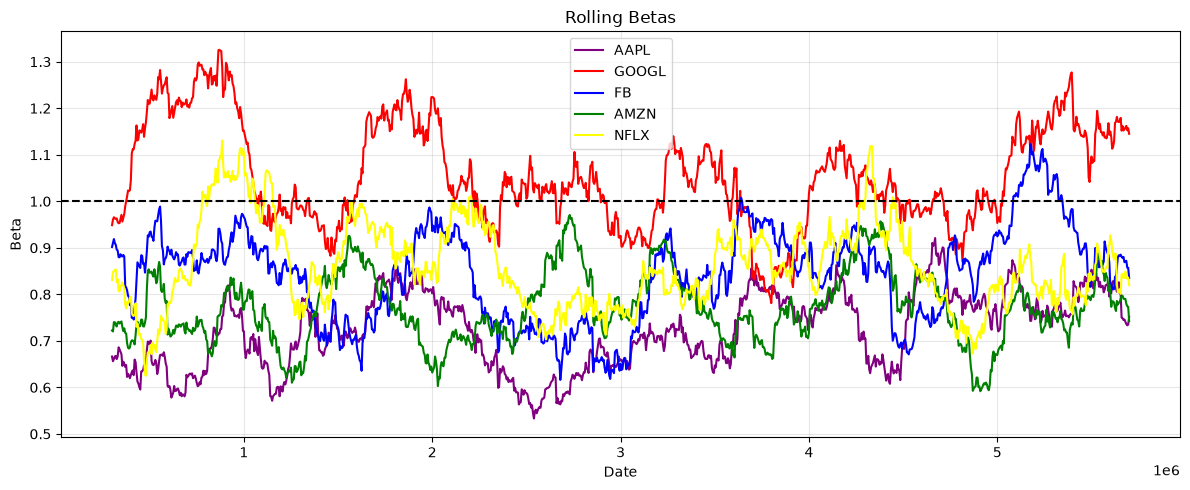

In [38]:
plt.figure(figsize=(12, 5))

plt.plot(rolling_betas['AAPL'], color="purple", label='AAPL')
plt.plot(rolling_betas['GOOGL'], color="red", label='GOOGL')
plt.plot(rolling_betas['FB'], color="blue", label='FB')
plt.plot(rolling_betas['AMZN'], color="green", label='AMZN')
plt.plot(rolling_betas['NFLX'], color="yellow", label='NFLX')

plt.axhline(1, color='black', linestyle='--')

plt.title("Rolling Betas")
plt.xlabel("Date")
plt.ylabel("Beta")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Task 3E — Select operational beta estimates

Create `latest_betas` from the final non-missing value of each rolling beta series. Reject non-finite values.

In [39]:
latest_betas = {}

for ticker in STOCKS:
    valid_betas = rolling_betas[ticker].dropna()

    if valid_betas.empty:
        raise ValueError(f"No beta estimate available for {ticker}")

    latest_beta = valid_betas.iloc[-1]

    if not np.isfinite(latest_beta):
        raise ValueError(f"Non-finite beta for {ticker}: {latest_beta}")

    latest_betas[ticker] = float(latest_beta)

print(latest_betas)

{'AAPL': 0.7516970189837003, 'FB': 0.8349865644653202, 'AMZN': 0.7423454122621881, 'NFLX': 0.8198534197187956, 'GOOGL': 1.1450422449377289}


### Rolling-risk reflection

Identify the stock whose beta varied most and explain why using a single constant beta can leave residual hedge risk.

In [40]:
beta_variation = rolling_betas.std()
most_variable_stock = beta_variation.idxmax()
print(rolling_betas)
print(beta_variation)
print("Most variable beta:", most_variable_stock)
print("Rolling-beta standard deviation:", beta_variation[most_variable_stock])

             AAPL        FB      AMZN      NFLX     GOOGL
date                                                     
5000          NaN       NaN       NaN       NaN       NaN
10000         NaN       NaN       NaN       NaN       NaN
15000         NaN       NaN       NaN       NaN       NaN
20000         NaN       NaN       NaN       NaN       NaN
25000         NaN       NaN       NaN       NaN       NaN
...           ...       ...       ...       ...       ...
5680000  0.741038  0.869778  0.790229  0.848997  1.158483
5685000  0.736220  0.872131  0.779599  0.834018  1.162095
5690000  0.733393  0.857290  0.774410  0.835832  1.152353
5695000  0.735023  0.856668  0.773223  0.836104  1.157028
5700000  0.751697  0.834987  0.742345  0.819853  1.145042

[1140 rows x 5 columns]
AAPL     0.080289
FB       0.100127
AMZN     0.076182
NFLX     0.092482
GOOGL    0.109224
dtype: float64
Most variable beta: GOOGL
Rolling-beta standard deviation: 0.10922380090428767


GOOGL had the most variable beta, measured by the standard deviation of its rolling beta estimates. A constant beta assumes that the stock’s relationship with FAANG never changes, so when the true beta rises or falls, the hedge becomes too small or too large and leaves residual market exposure.

_Write your answer here before continuing._

# Challenge 3 — Threshold-based portfolio hedging

Repeat adaptive market making, but do not hedge every fill. After each request, calculate current beta-adjusted stock exposure. Trade FAANG only when residual exposure exceeds a specified dollar threshold.

In [41]:
mm = MarketMaker.mm()
prices = Data.get_price_series('PricestoFeedserverEtfUpdate', True)
price_requests = Data.get_price_requests('PriceRequeststoFeedserverExtended')
hf.reset(seed=3033)
HEDGE_THRESHOLD = 1_000_000.0

In [42]:
print(prices.head())
print(price_requests[:2])

        AAPL     AMZN   FAANG      FB    GOOGL    NFLX
date                                                  
0      74.70  1953.00  100.00  196.44  1386.00  381.05
5000   74.04  1943.96   99.58  197.35  1376.61  381.11
10000  74.42  1935.27  100.06  197.76  1381.43  383.00
15000  75.27  1939.40  100.52  196.64  1400.90  382.86
20000  75.34  1971.73  100.90  198.90  1412.23  382.71
[['GOOGL', 20000, 6592], ['AMZN', 25000, 4627]]


In [43]:
class ETFOrder:
    def __init__(self, ticker, trade_volume, ref_price, action, date):
        self.ticker = ticker
        self.trade_volume = trade_volume
        self.ref_price = ref_price
        self.action = action
        self.date = date

## Task 3F — Hedging loop

Reuse your adaptive quote logic. After every request, calculate stock beta exposure using `latest_betas` and current prices. Compute exposure after including the existing FAANG position. If its absolute value exceeds `HEDGE_THRESHOLD`, trade enough FAANG to bring it toward zero. Record pre-hedge and post-hedge exposure, dates, and ETF position.

In [44]:
pre_hedge_exposure = []
post_hedge_exposure = []
hedge_dates = []
etf_positions = []

for ticker, date, volume in price_requests:
    ref_price = prices.at[date, ticker]
    position = mm.position(ticker)
    bid, offer = adaptive_quote(ref_price, volume, position, POSITION_LIMIT)
    quote = QuoteTicket(ticker, volume, ref_price, bid, offer, date)
    mm.add_quoted_trade(quote)
    response = hf.show(quote)

    if response.hf_action in {'buy', 'sell'}:
        if response.hf_action == 'buy':
            mm_action = 'sell'
            future_position = position - volume
        else:
            mm_action = 'buy'
            future_position = position + volume

        if abs(future_position) <= POSITION_LIMIT:
            trade = ExecutionRecord(response.ticker, response.trade_volume, response.trade_price, mm_action, response.ref_price, response.bid_price, response.offer_price, response.date)
            mm.add_trade(trade)

    stock_beta_exposure = 0
    for stock in STOCKS:
        stock_beta_exposure += mm.position(stock) * prices.at[date, stock] * latest_betas[stock]

    etf_price = prices.at[date, ETF]
    exposure_before = stock_beta_exposure + mm.position(ETF) * etf_price
    pre_hedge_exposure.append(exposure_before)

    if abs(exposure_before) > HEDGE_THRESHOLD:
        hedge_action = 'sell' if exposure_before > 0 else 'buy'
        hedge_volume = abs(exposure_before) / etf_price
        order = ETFOrder(ETF, hedge_volume, etf_price, hedge_action, date)
        executed_trade = Exchange.execute(order)
        mm.update_ETF_position(executed_trade)

    exposure_after = stock_beta_exposure + mm.position(ETF) * etf_price
    post_hedge_exposure.append(exposure_after)
    hedge_dates.append(date)
    etf_positions.append(mm.position(ETF))

### Hedge summary

Report requests, completed stock trades, ETF hedge trades, and the fraction of observations above the threshold after hedging.

In [45]:
request_count = len(price_requests)
completed_stock_trades = len(mm.completed_trades)
etf_hedge_trades = len(mm.ETF_positions)

above_threshold = [
    abs(exposure) > HEDGE_THRESHOLD
    for exposure in post_hedge_exposure
]

fraction_above_threshold = (
    sum(above_threshold) / len(above_threshold)
    if above_threshold else 0
)

print("Requests:", request_count)
print("Completed stock trades:", completed_stock_trades)
print("ETF hedge trades:", etf_hedge_trades)
print(f"Fraction above threshold after hedging: {fraction_above_threshold:.2%}")

Requests: 520
Completed stock trades: 435
ETF hedge trades: 256
Fraction above threshold after hedging: 0.00%


## Task 3G — Compare exposure before and after hedging

Plot both series on one chart with horizontal lines at zero and the positive/negative thresholds.

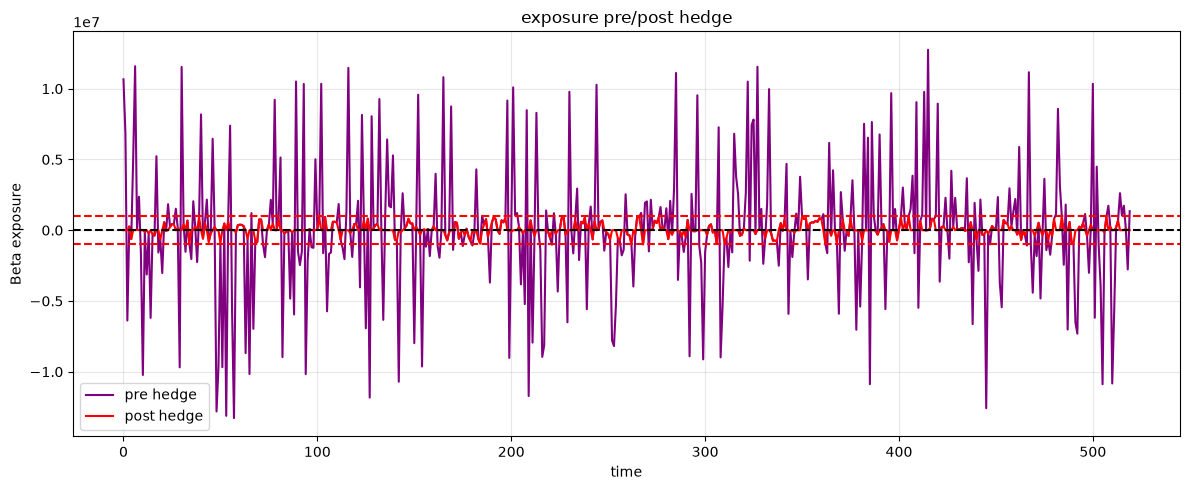

In [46]:
plt.figure(figsize=(12, 5))

plt.plot(pre_hedge_exposure, color="purple", label='pre hedge')
plt.plot(post_hedge_exposure, color="red", label='post hedge')


plt.axhline(0, color='black', linestyle='--')
plt.axhline(HEDGE_THRESHOLD, color='red', linestyle='--')
plt.axhline(-HEDGE_THRESHOLD, color='red', linestyle='--')

plt.title("exposure pre/post hedge")
plt.xlabel("time")
plt.ylabel("Beta exposure")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Task 3H — Plot ETF inventory

Plot the signed FAANG position and mark dates when hedge trades occurred.

In [62]:
print(mm.ETF_positions)

[ExecutedTrade(ticker='FAANG', trade_volume=105645.97977279437, trade_price=100.9, action='sell', date=20000, ref_price=100.9), ExecutedTrade(ticker='FAANG', trade_volume=66992.29069126914, trade_price=101.86, action='sell', date=25000, ref_price=101.86), ExecutedTrade(ticker='FAANG', trade_volume=61314.254087253474, trade_price=104.08, action='buy', date=40000, ref_price=104.08), ExecutedTrade(ticker='FAANG', trade_volume=48580.543748380645, trade_price=103.5, action='sell', date=55000, ref_price=103.5), ExecutedTrade(ticker='FAANG', trade_volume=111680.11840017138, trade_price=103.77, action='sell', date=60000, ref_price=103.77), ExecutedTrade(ticker='FAANG', trade_volume=22071.656100576343, trade_price=107.27, action='sell', date=80000, ref_price=107.27), ExecutedTrade(ticker='FAANG', trade_volume=15528.264656683119, trade_price=107.27, action='buy', date=80000, ref_price=107.27), ExecutedTrade(ticker='FAANG', trade_volume=95973.38410634921, trade_price=106.6, action='buy', date=950

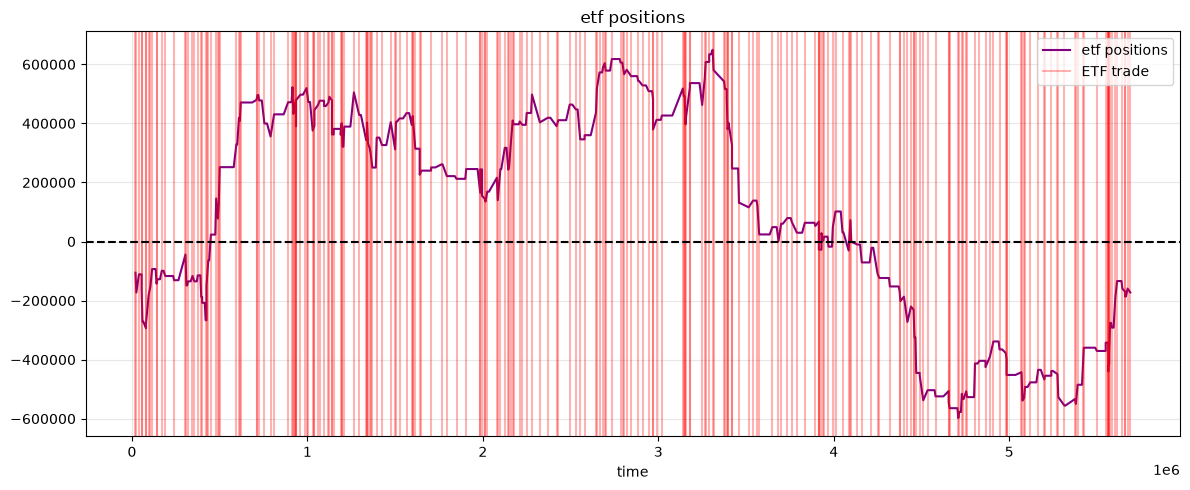

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(hedge_dates, etf_positions, color="purple", label='etf positions')

for i, trade in enumerate(mm.ETF_positions):
    plt.axvline(
        trade.date,
        color="red",
        alpha=0.3,
        label="ETF trade" if i == 0 else None
    )

plt.axhline(0, color='black', linestyle='--')

plt.title("etf positions")
plt.xlabel("time")
plt.ylabel("")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Task 3I — Risk metrics

Calculate mean absolute exposure, maximum absolute exposure, 95th percentile absolute exposure, and the number of ETF hedge trades.

In [48]:
absolute_exposure = np.abs(post_hedge_exposure)

mean_absolute_exposure = np.mean(absolute_exposure)
maximum_absolute_exposure = np.max(absolute_exposure)
percentile_95_exposure = np.percentile(absolute_exposure, 95)
etf_hedge_count = len(mm.ETF_positions)

print(f"Mean absolute exposure: ${mean_absolute_exposure:,.2f}")
print(f"Maximum absolute exposure: ${maximum_absolute_exposure:,.2f}")
print(f"95th percentile absolute exposure: ${percentile_95_exposure:,.2f}")
print("ETF hedge trades:", etf_hedge_count)

Mean absolute exposure: $221,630.18
Maximum absolute exposure: $999,210.90
95th percentile absolute exposure: $852,512.11
ETF hedge trades: 256


### Challenge 3 reflection

Compare hedging every fill with hedging only after a threshold breach. Discuss transaction count, residual risk, and operational complexity.

Hedging after every fill minimizes residual market exposure but creates more transactions, increasing costs and operational workload. Threshold-based hedging executes fewer trades and therefore reduces transaction costs, but deliberately carries some unhedged exposure between hedge events. A large client order can cause exposure to jump substantially beyond the threshold before the hedge is executed, so choosing an appropriate threshold is an important risk-management decision.

_Write your answer here before continuing._

# Challenge 4 — Z-score ETF relative-value strategy

Build a real-versus-synthetic ETF spread, standardize it with rolling statistics, and trade only statistically unusual deviations.

In [49]:
components = STOCKS
initial_prices = wide_prices.loc[wide_prices.index[0], components]
weights = {ticker: 20.0 / initial_prices[ticker] for ticker in components}
synthetic = sum(wide_prices[ticker] * weights[ticker] for ticker in components)
real = wide_prices[ETF]
spread = real - synthetic

## Task 4A — Rolling z-score

Using a 60-observation rolling window, calculate rolling spread mean, rolling spread standard deviation, and `zscore`. Avoid division by zero and do not use future data.

In [50]:
mean = spread.rolling(WINDOW).mean()
std = spread.rolling(WINDOW).std()
zscore = (spread - mean) / std

print(zscore)

date
0               NaN
5000            NaN
10000           NaN
15000           NaN
20000           NaN
             ...   
5680000    0.812798
5685000    1.960569
5690000    0.836959
5695000    0.191097
5700000   -1.235516
Length: 1141, dtype: float64


## Task 4B — Visualize the signal

Plot z-score with horizontal lines at +2, -2, and 0. Clearly show the initial region where the rolling signal is unavailable.

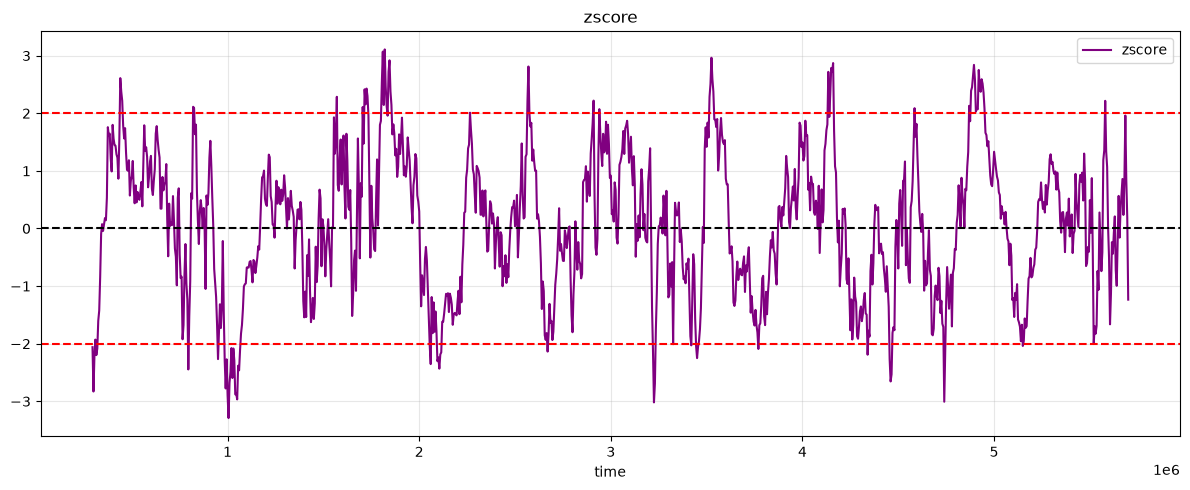

In [51]:
plt.figure(figsize=(12, 5))

plt.plot(zscore, color="purple", label='zscore')


plt.axhline(0, color='black', linestyle='--')
plt.axhline(2, color='red', linestyle='--')
plt.axhline(-2, color='red', linestyle='--')

plt.title("zscore")
plt.xlabel("time")
plt.ylabel("")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Trading rules

- Enter short real/long synthetic when z-score exceeds +2.
- Enter long real/short synthetic when z-score falls below -2.
- Exit when z-score crosses zero.
- Permit at most one open pair.
- Size one pair from a fixed $25,000 real-ETF notional at entry.
- Store exact entry quantities and use them for exit.
- Force liquidation at the final date.
- Do not trade until the rolling z-score is available.

In [52]:
from AmplifyArbitrageTrading import HedgeFund as ArbitrageHedgeFund

account = ArbitrageHedgeFund.hf(
    commission_percentage=0.001,
    data=wide_prices,
)
PAIR_NOTIONAL = 25_000.0

## Task 4C — Implement the z-score strategy

Implement entry, exact quantity storage, state-aware exit, and final liquidation with `account.execute_order`. Track entry and exit dates plus their z-scores in `strategy_events`.

In [53]:
account = ArbitrageHedgeFund.hf(commission_percentage=0.001, data=wide_prices)
strategy_events = []
open_pair = None

for date, score in zscore.items():
    if not np.isfinite(score):
        continue

    if open_pair is None:
        real_quantity = PAIR_NOTIONAL / real.loc[date]
        synthetic_scale = PAIR_NOTIONAL / synthetic.loc[date]
        component_quantities = {ticker: synthetic_scale * weights[ticker] for ticker in STOCKS}

        if score > 2:
            account.execute_order(ETF, real_quantity, 'sell', date)
            for ticker in STOCKS:
                account.execute_order(ticker, component_quantities[ticker], 'buy', date)
            open_pair = {'side': 'short_real', 'real_quantity': real_quantity, 'component_quantities': component_quantities}
            strategy_events.append({'event': 'entry', 'date': date, 'zscore': float(score), 'side': 'short_real'})

        elif score < -2:
            account.execute_order(ETF, real_quantity, 'buy', date)
            for ticker in STOCKS:
                account.execute_order(ticker, component_quantities[ticker], 'sell', date)
            open_pair = {'side': 'long_real', 'real_quantity': real_quantity, 'component_quantities': component_quantities}
            strategy_events.append({'event': 'entry', 'date': date, 'zscore': float(score), 'side': 'long_real'})

    elif open_pair['side'] == 'short_real' and score <= 0:
        account.execute_order(ETF, open_pair['real_quantity'], 'buy', date)
        for ticker in STOCKS:
            account.execute_order(ticker, open_pair['component_quantities'][ticker], 'sell', date)
        strategy_events.append({'event': 'exit', 'date': date, 'zscore': float(score), 'side': open_pair['side']})
        open_pair = None

    elif open_pair['side'] == 'long_real' and score >= 0:
        account.execute_order(ETF, open_pair['real_quantity'], 'sell', date)
        for ticker in STOCKS:
            account.execute_order(ticker, open_pair['component_quantities'][ticker], 'buy', date)
        strategy_events.append({'event': 'exit', 'date': date, 'zscore': float(score), 'side': open_pair['side']})
        open_pair = None

if open_pair is not None:
    final_date = zscore.index[-1]
    final_score = zscore.loc[final_date]
    if open_pair['side'] == 'short_real':
        account.execute_order(ETF, open_pair['real_quantity'], 'buy', final_date)
        for ticker in STOCKS:
            account.execute_order(ticker, open_pair['component_quantities'][ticker], 'sell', final_date)
    else:
        account.execute_order(ETF, open_pair['real_quantity'], 'sell', final_date)
        for ticker in STOCKS:
            account.execute_order(ticker, open_pair['component_quantities'][ticker], 'buy', final_date)
    strategy_events.append({'event': 'final_liquidation', 'date': final_date, 'zscore': float(final_score), 'side': open_pair['side']})
    open_pair = None

## Task 4D — Net P&L and reconciliation

Calculate gross realized P&L, total commissions, net P&L, and ending balance. Confirm that net P&L equals ending balance minus initial balance after liquidation.

In [54]:
gross_realized_pnl = sum(position.profit_loss for position in account.current_positions.values())

total_commissions = sum(position.commission_costs for position in account.current_positions.values())

net_pnl = gross_realized_pnl - total_commissions

ending_balance = account.balance
balance_change = ending_balance - account.initial_balance

print(f"Gross realized P&L: ${gross_realized_pnl:,.2f}")
print(f"Total commissions: ${total_commissions:,.2f}")
print(f"Net P&L: ${net_pnl:,.2f}")
print(f"Ending balance: ${ending_balance:,.2f}")
print(f"Balance change: ${balance_change:,.2f}")
print("Reconciles:", np.isclose(net_pnl, balance_change))

Gross realized P&L: $8,050.53
Total commissions: $2,803.26
Net P&L: $5,247.28
Ending balance: $20,005,247.28
Balance change: $5,247.28
Reconciles: True


## Task 4E — Trade audit

Create a compact DataFrame from `strategy_events`, display one component's transaction history, and confirm every final position is flat.

In [55]:
strategy_events_df = pd.DataFrame(strategy_events).set_index("date").sort_index()
print(strategy_events_df.head(4))

        event    zscore        side
date                               
295000  entry -2.060425   long_real
345000   exit  0.074971   long_real
440000  entry  2.610057  short_real
690000   exit -0.482541  short_real


## Task 4F — Strategy diagnostics

Report number of completed pairs, average holding period, win rate by pair, and largest net losing pair. State any assumptions used to assign commissions across pairs.

In [56]:
trade_rows = []
for ticker, position in account.current_positions.items():
    for trade in position.trade_history:
        trade_rows.append({'ticker': ticker, **trade})

trades_df = pd.DataFrame(trade_rows)
date_number = {date: i for i, date in enumerate(wide_prices.index)}
pair_results = []
entry_event = None
pair_number = 0

for event in strategy_events:
    if event['event'] == 'entry':
        if entry_event is not None:
            raise ValueError('Entry found while another pair is open')
        entry_event = event
    elif event['event'] in {'exit', 'final_liquidation'}:
        if entry_event is None:
            raise ValueError('Exit found without an entry')
        pair_number += 1
        entry_date = entry_event['date']
        exit_date = event['date']
        pair_trades = trades_df[trades_df['date'].isin([entry_date, exit_date])].copy()
        pair_trades['cash_flow'] = np.where(pair_trades['action'] == 'SELL', pair_trades['price'] * pair_trades['volume'], -pair_trades['price'] * pair_trades['volume'])
        gross_pnl = pair_trades['cash_flow'].sum()
        commissions = pair_trades['commission'].sum()
        net_pnl = gross_pnl - commissions
        pair_results.append({'pair': pair_number, 'side': entry_event['side'], 'entry_date': entry_date, 'exit_date': exit_date, 'entry_zscore': entry_event['zscore'], 'exit_zscore': event['zscore'], 'holding_period': exit_date - entry_date, 'holding_observations': date_number[exit_date] - date_number[entry_date], 'gross_pnl': gross_pnl, 'commissions': commissions, 'net_pnl': net_pnl})
        entry_event = None

if entry_event is not None:
    raise ValueError('A pair remains open')

pairs_df = pd.DataFrame(pair_results).set_index('pair')
completed_pairs = len(pairs_df)
average_holding_period = pairs_df['holding_observations'].mean()
win_rate = (pairs_df['net_pnl'] > 0).mean()
largest_net_losing_pair = pairs_df[pairs_df['net_pnl'] < 0].nsmallest(1, 'net_pnl')
commission_assumption = 'All commissions from the six entry legs and six closing legs are assigned to that pair because only one pair can be open and no open-pair rebalancing occurs.'

print('Completed pairs:', completed_pairs)
print(f'Average holding period: {average_holding_period:.2f} observations')
print(f'Win rate: {win_rate:.2%}')
print('Largest net losing pair:')
display(largest_net_losing_pair)
print('Commission assumption:', commission_assumption)

Completed pairs: 28
Average holding period: 15.96 observations
Win rate: 89.29%
Largest net losing pair:


,side,entry_date,exit_date,entry_zscore,exit_zscore,holding_period,holding_observations,gross_pnl,commissions,net_pnl
pair,,,,,,,,,,
5,long_real,950000,1170000,-2.267387,0.044565,220000,44,-129.275875,95.311013,-224.586889


Commission assumption: All commissions from the six entry legs and six closing legs are assigned to that pair because only one pair can be open and no open-pair rebalancing occurs.


## Optional stress test

Without changing the main results, describe how entries and P&L might change for thresholds of 1.5 and 2.5 or for doubled commissions.

In [57]:
def run_stress_scenario(entry_threshold, commission_rate):
    stress_account = ArbitrageHedgeFund.hf(commission_percentage=commission_rate, data=wide_prices)
    stress_pair = None
    stress_entries = 0
    stress_completed_pairs = 0
    for date, score in zscore.items():
        if not np.isfinite(score):
            continue
        if stress_pair is None:
            real_quantity = PAIR_NOTIONAL / real.loc[date]
            synthetic_scale = PAIR_NOTIONAL / synthetic.loc[date]
            component_quantities = {ticker: synthetic_scale * weights[ticker] for ticker in STOCKS}
            if score > entry_threshold:
                stress_account.execute_order(ETF, real_quantity, 'sell', date)
                for ticker in STOCKS:
                    stress_account.execute_order(ticker, component_quantities[ticker], 'buy', date)
                stress_pair = {'side': 'short_real', 'real_quantity': real_quantity, 'component_quantities': component_quantities}
                stress_entries += 1
            elif score < -entry_threshold:
                stress_account.execute_order(ETF, real_quantity, 'buy', date)
                for ticker in STOCKS:
                    stress_account.execute_order(ticker, component_quantities[ticker], 'sell', date)
                stress_pair = {'side': 'long_real', 'real_quantity': real_quantity, 'component_quantities': component_quantities}
                stress_entries += 1
        elif stress_pair['side'] == 'short_real' and score <= 0:
            stress_account.execute_order(ETF, stress_pair['real_quantity'], 'buy', date)
            for ticker in STOCKS:
                stress_account.execute_order(ticker, stress_pair['component_quantities'][ticker], 'sell', date)
            stress_pair = None
            stress_completed_pairs += 1
        elif stress_pair['side'] == 'long_real' and score >= 0:
            stress_account.execute_order(ETF, stress_pair['real_quantity'], 'sell', date)
            for ticker in STOCKS:
                stress_account.execute_order(ticker, stress_pair['component_quantities'][ticker], 'buy', date)
            stress_pair = None
            stress_completed_pairs += 1
    if stress_pair is not None:
        final_date = zscore.index[-1]
        if stress_pair['side'] == 'short_real':
            stress_account.execute_order(ETF, stress_pair['real_quantity'], 'buy', final_date)
            for ticker in STOCKS:
                stress_account.execute_order(ticker, stress_pair['component_quantities'][ticker], 'sell', final_date)
        else:
            stress_account.execute_order(ETF, stress_pair['real_quantity'], 'sell', final_date)
            for ticker in STOCKS:
                stress_account.execute_order(ticker, stress_pair['component_quantities'][ticker], 'buy', final_date)
        stress_pair = None
        stress_completed_pairs += 1
    gross_pnl = sum(position.profit_loss for position in stress_account.current_positions.values())
    commissions = sum(position.commission_costs for position in stress_account.current_positions.values())
    net_pnl = gross_pnl - commissions
    return {'entry_threshold': entry_threshold, 'commission_rate': commission_rate, 'entries': stress_entries, 'completed_pairs': stress_completed_pairs, 'gross_pnl': gross_pnl, 'commissions': commissions, 'net_pnl': net_pnl}

stress_scenarios = [{'scenario': 'baseline', 'entry_threshold': 2.0, 'commission_rate': 0.001}, {'scenario': 'threshold_1.5', 'entry_threshold': 1.5, 'commission_rate': 0.001}, {'scenario': 'threshold_2.5', 'entry_threshold': 2.5, 'commission_rate': 0.001}, {'scenario': 'double_commission', 'entry_threshold': 2.0, 'commission_rate': 0.002}]
stress_rows = []
for scenario in stress_scenarios:
    result = run_stress_scenario(scenario['entry_threshold'], scenario['commission_rate'])
    stress_rows.append({'scenario': scenario['scenario'], **result})
stress_results = pd.DataFrame(stress_rows).set_index('scenario')
stress_results['entry_change_vs_baseline'] = stress_results['entries'] - stress_results.loc['baseline', 'entries']
stress_results['net_pnl_change_vs_baseline'] = stress_results['net_pnl'] - stress_results.loc['baseline', 'net_pnl']
display(stress_results)

,entry_threshold,commission_rate,entries,completed_pairs,gross_pnl,commissions,net_pnl,entry_change_vs_baseline,net_pnl_change_vs_baseline
scenario,,,,,,,,,
baseline,2.0,0.001,28,28,8050.532857,2803.256521,5247.276336,0,0.000000
threshold_1.5,1.5,0.001,37,37,8272.068290,3694.547304,4577.520986,9,-669.755350
threshold_2.5,2.5,0.001,11,11,3203.239130,1107.356686,2095.882444,-17,-3151.393892
double_commission,2.0,0.002,28,28,8050.532857,5606.513042,2444.019815,0,-2803.256521


## Final written assessment

Answer briefly:

1. Which model assumption is least realistic?
2. Where could look-ahead bias enter this notebook?
3. Why can a profitable backtest still be a poor live strategy?
4. Which single additional risk control would you add first?

The least realistic assumption is that every order executes immediately at the reference price with unlimited liquidity and no slippage or market impact.

Look-ahead bias could enter by applying the final latest_betas to earlier dates or by calculating a z-score from the current closing price and assuming execution at that same price.

A profitable backtest can perform poorly live because of slippage, changing market relationships, delayed execution, underestimated costs, or overfitting to historical data.

I would first add a hard maximum loss per pair. If an open pair loses more than a predetermined dollar amount, every leg would be liquidated even if the z-score had not crossed zero.

_Write your answers here._

# Submission checklist

- Restart the kernel and run all completed cells.
- Remove remaining `NotImplementedError` statements.
- Confirm quote, execution, and hedge logs have no accidental duplicates.
- Confirm all final arbitrage positions are flat.
- Check every plot has labels, title, legend where appropriate, and aligned data.
- Keep explanations concise and specific to your results.

In [60]:
# Final structural reminder; this is not a grader.
print('Notebook:', 'Quant Assesment2.ipynb')
print('Seed:', RANDOM_SEED)
print('Complete the checklist above before review.')

Notebook: Quant Assesment2.ipynb
Seed: 3030
Complete the checklist above before review.


## End of assessment

Save this completed attempt under a new filename if you want to preserve a clean copy for another timed run.

In [61]:
print('Assessment 2 reached its final cell.')

Assessment 2 reached its final cell.
